# Comparing conditions with replicates

The tutorial compares how genes change with the distance to an anchor between two conditions, when each condition has several biological replicates. The replicates, not the cells, are the unit of comparison. Start here if you have two or more donors, organoids or animals per condition.

The data are from Legnini et al. (2023): sections of neural organoid-like cultures with 88 measured genes, 4 organoids in which SHH was induced and 4 controls. The anchor cells are the cells with the highest SHH expression, and every other cell gets its distance to the nearest anchor cell.

The tutorial has five steps:

1. Compute the distances, and make each organoid one replicate.
2. Run three tests per gene: shape, level and slope.
3. Look at the curves and a volcano plot of the top genes.
4. Test gene sets, which can detect changes that are too weak for single genes.
5. Check the tests on a random split of the organoids, where no gene truly differs.

With 4 replicates per condition, only genes with strong effects pass a correction for testing 88 genes. Read the per-gene results as a ranked list of candidates, and use the gene-set tests for calls about pathways.

In [1]:
# One BLAS thread per process; set before numpy is imported.
import os

for var in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ[var] = "1"

import numpy as np
import pandas as pd
import scanpy as sc
import squidpy as sq

import diffsvg as dvg

N_WORKERS = int(os.environ.get("DIFFSVG_WORKERS", 4))
LAYER = "log1p_norm"

## 1. Distances and replicates

`squidpy.tl.var_by_distance` gives every cell its distance to the closest anchor cell of its own section and scales it to 0 to 1 per section, so 0 is at the anchor and 1 is the farthest cell of that section. It stores the distances, together with the covariates, in `adata.obsm["design_matrix"]`. The distance column is named after the anchor group, here `"True"`. The anchor is the top 1% of SHH expression over all cells.

**The anchor means different things in the two conditions.** In control organoids, the anchor cells are a few cells with endogenous SHH. In the SHH organoids, SHH is expressed widely, so most anchor cells come from them. Differences in shape therefore mix the effect of SHH with the different meaning of "distance to the anchor", and single-gene results need that caveat.

The 17 sections come from 8 organoids, and sections of the same organoid are not independent. `bin_obs(..., sample="organoid")` therefore treats each organoid as one replicate. The section `slide1_A2-2` has no anchor cells, so it drops out.

In [2]:
adata = dvg.datasets.legnini23()  # downloads about 90 MB once, then reads from the cache

shh = sc.get.obs_df(adata, "SHH")["SHH"].to_numpy()
adata.obs["SHH+"] = (shh > np.percentile(shh, 99)).astype(str)

sq.tl.var_by_distance(
    adata, cluster_key="SHH+", groups="True", library_key="sample", covariates=["condition", "organoid"]
)
design = adata.obsm["design_matrix"]
design["organoid"] = design["organoid"].astype(str)
design.groupby("organoid", observed=True)["condition"].first().value_counts()

condition
Ctrl    4
SHH     4
Name: count, dtype: int64

In [3]:
dvg.pp.bin_obs(adata, anchor="True", condition="condition", layer=LAYER, sample="organoid")
setup = dvg.tl.setup_model(adata)

## 2. Shape, level and slope tests

The model fits one smooth curve of expression against distance per gene and condition, plus one random curve per organoid, so the conditions are compared against the variation between organoids. Each test compares the two condition curves over the distances where both conditions have cells. Pick the test that matches your question before you look at the results:

- `test="parallel"` (shape) asks whether the curves differ by more than a shift up or down.
- `test="level"` asks whether one curve is higher on average.
- `test="slope"` asks whether the gap between the curves grows or shrinks with distance.

The conditions are compared as SHH minus Ctrl, in sorted order of the labels. Each test is corrected for multiple testing over the genes (Benjamini-Hochberg, columns ending in `_pval_adj`), not over the three tests. With replicates, `tau` defaults to 0, so any difference counts; set `tau` to ignore differences smaller than that.

`fit_model(..., inplace=False)` returns the per-gene table together with the curves and the settings, and leaves `adata` unchanged. The last fit runs in place, so the curves are stored for plotting.

In [4]:
results = {}
for test in ("level", "slope"):
    stats, _curves, _params = dvg.tl.fit_model(
        adata, setup, test=test, n_workers=N_WORKERS, progressbar=False, inplace=False
    )
    results[test] = stats

dvg.tl.fit_model(adata, setup, test="parallel", n_workers=N_WORKERS, progressbar=False)
results["parallel"] = adata.varm["dsvg_stats"]

pd.DataFrame(
    {
        test: {
            "p < 0.05": int((stats[f"{test}_pval"] < 0.05).sum()),
            "FDR < 0.05": int((stats[f"{test}_pval_adj"] < 0.05).sum()),
        }
        for test, stats in results.items()
    }
)

,level,slope,parallel
p < 0.05,20,9,18
FDR < 0.05,11,0,6


The shape test ranks the genes by how much the gap between the curves changes beyond a constant shift. `shape_diff` measures that change in log-expression units over the distance range; for a gap that changes linearly it equals the change in slope. `slope_diff` is the slope of the gap, SHH minus Ctrl.

In [5]:
shape = results["parallel"].sort_values("parallel_pval")
shape[["shape_diff", "slope_diff", "parallel_pval", "parallel_pval_adj"]].head(10)

,shape_diff,slope_diff,parallel_pval,parallel_pval_adj
FOXA2,0.325483,0.198719,9.390106e-07,0.000083
HHIP,1.417356,0.976790,1.204555e-04,0.005300
PAX7,1.269618,-0.996571,2.614018e-04,0.007668
NEUROG2,1.017012,0.573022,5.412339e-04,0.010921
GLI1,1.231383,1.036409,6.205072e-04,0.010921
TBP,0.440008,-0.377586,1.932708e-03,0.028346
FOXA1,0.135870,0.078187,4.075397e-03,0.051234
Circ.RMST,0.960115,-0.779381,7.489264e-03,0.082195
DBX2,1.011231,0.621912,8.406322e-03,0.082195
PTCH1,1.051677,0.264435,2.171768e-02,0.191116


The top genes are SHH targets (FOXA2, HHIP, GLI1) and patterning genes (PAX7, NEUROG2). TBP, a housekeeping gene, is also among the hits. A change in a housekeeping gene can come from differences in cell composition or normalisation between the conditions, so check such genes before you trust a whole list.

The level test finds the genes whose overall expression changes. The SHH-repressed genes PAX7, IRX3 and GLI3 go down, and the ventral genes NKX6.1 and NKX6.2, the neuronal gene NEUROD1 and the motor neuron marker CHAT go up, which is the ventral shift expected from SHH. Some hits have very small effects, e.g. BCL11B with a `level_diff` of about -0.01 log units. With `tau = 0` significance doesn't mean a relevant effect size, so sort by effect size as well.

In [6]:
level = results["level"].sort_values("level_pval")
level[["level_diff", "level_pval", "level_pval_adj"]].head(10)

,level_diff,level_pval,level_pval_adj
gene,,,
PAX7,-2.151143,0.000022,0.001977
IRX3,-1.363535,0.000047,0.002075
BMP4,-0.097084,0.000397,0.011658
GLI3,-0.712198,0.000767,0.016882
BCL11B,-0.009320,0.001765,0.025727
NKX6.2,0.549647,0.001821,0.025727
NEUROD1,0.406592,0.002046,0.025727
NKX6.1,1.883516,0.003328,0.036414
Circ.RMST,-1.273850,0.003741,0.036414


## 3. Curves and volcano plot

The volcano plot shows the slope of the gap between the curves against the significance of the shape test. Blue genes have an SHH minus Ctrl difference that increases with the distance from the anchor, and red genes one that decreases. Genes are coloured when their unadjusted p-value is below 0.05, the dashed line; use `parallel_pval_adj` for calls.

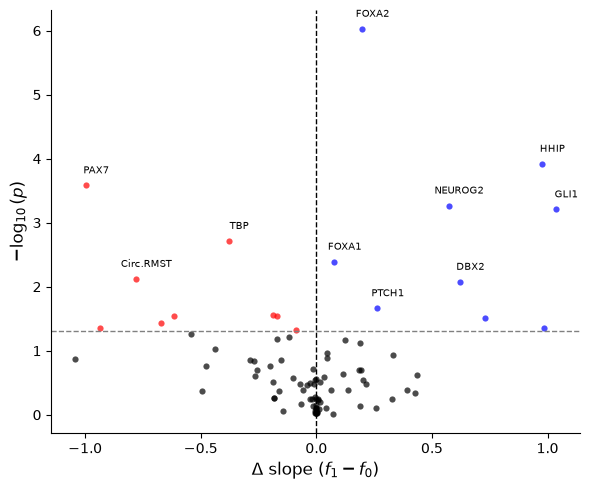

In [7]:
dvg.pl.plot_volcano(results["parallel"], n_label=10, figsize=(6, 5));

The curves show the posterior mean expression per condition with a 94% credible band. FOXA2 and HHIP are highest in the control organoids close to the anchor and fall within the first fifth of the distance, so the controls have a small ventral domain around their few SHH cells. In the SHH organoids these genes are low and nearly flat, so the gap between the conditions is most negative at the anchor and the slope difference is positive. PAX7, which SHH represses, is almost absent from the SHH organoids, while in the controls it rises away from the anchor. NEUROG2 is higher in the SHH organoids away from the anchor.

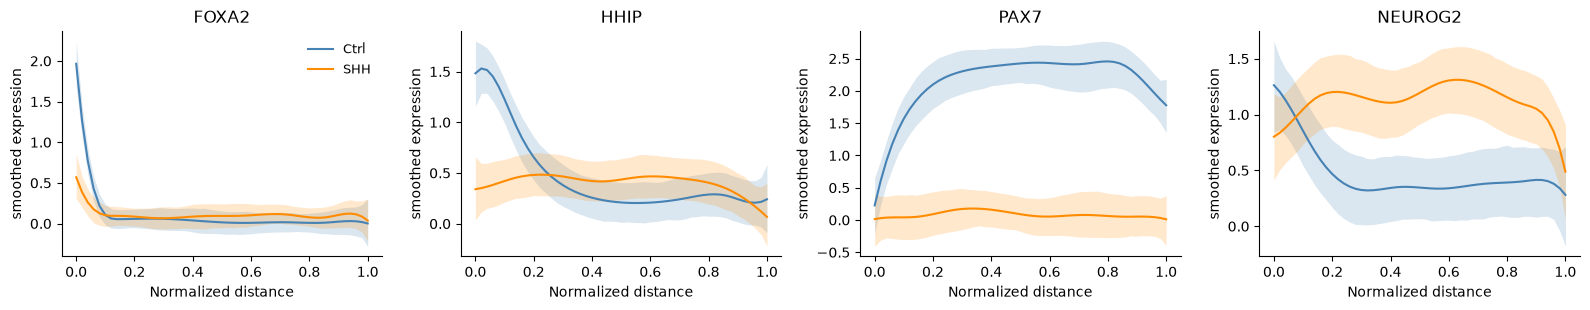

In [8]:
dvg.pl.plot_prediction_curve(adata, gene=list(shape.index[:4]));

## 4. Gene sets

`tl.gene_set_test` summarises each organoid by one level and one slope per gene and asks whether the genes of a set change together between the conditions. It uses a rotation test, which keeps the correlation between genes and treats each organoid as one replicate. The test is self-contained, which means that it asks whether the genes of the set change at all, so a set that contains a few strongly changed genes is significant even if the rest don't change. To ask whether a set changes more than the rest of the panel, use `method="ulm"`.

The sets below are SHH targets, induced by SHH, and SHH-repressed genes (class I genes of the neural tube). Any gene list or decoupler network works as a set.

In [9]:
genes = set(adata.var_names)
gene_sets = {
    "SHH targets": [g for g in ["GLI1", "PTCH1", "PTCH2", "HHIP", "FOXA2", "NKX2-2", "NKX6.1", "NKX6.2", "OLIG2", "NKX2-1"] if g in genes],
    "SHH-repressed": [g for g in ["PAX7", "PAX6", "PAX3", "IRX3", "MSX1", "MSX2", "DBX1", "DBX2", "GLI3", "WNT1"] if g in genes],
}  # fmt: skip
for name, members in gene_sets.items():
    print(f"{name}: {', '.join(members)}")
dvg.tl.gene_set_test(setup, gene_sets)

SHH targets: GLI1, PTCH1, HHIP, FOXA2, NKX6.1, NKX6.2, OLIG2
SHH-repressed: PAX7, PAX6, IRX3, MSX2, DBX1, DBX2, GLI3


,summary,set,size,mean_t,pval_up,pval_down,pval_mixed,pval,pval_adj
0,level,SHH-repressed,7,-8.670715,1.0000,0.0001,0.0001,0.0002,0.0004
1,level,SHH targets,7,4.095945,0.0002,0.9999,0.0004,0.0004,0.0004
2,slope,SHH targets,7,2.719620,0.0039,0.9962,0.0072,0.0078,0.0156
3,slope,SHH-repressed,7,-0.198673,0.6405,0.3596,0.0068,0.7192,0.7192


Columns: `mean_t` is the mean per-gene t statistic of the set (positive: higher or steeper in SHH). `pval_up` and `pval_down` test whether the set moves up or down together, and `pval` is the two-sided version, `2 * min(pval_up, pval_down)`. `pval_mixed` tests whether the genes change in either direction, without a common direction. `pval_adj` corrects `pval` over the sets of each summary. The smallest possible p-value is `1 / (n_rotations + 1)`, here 0.0001.

In the level summary, SHH targets go up and SHH-repressed genes go down in the SHH organoids. In the slope summary, SHH targets have a positive slope difference, which is the lost gradient seen in the curves. The SHH-repressed genes have no common slope change (`pval`), but their slopes change in both directions (`pval_mixed`). Most genes in these sets already pass on their own; the set test is most useful when the single genes don't.

## 5. Check with a random split

If the organoids are split into two groups at random, no gene truly differs between the groups. The split below puts 2 SHH and 2 control organoids in each group, so the real effect cancels out. A test with exact p-values would put about 5% of the genes, here about 4, below 0.05 and rarely any gene below FDR 0.05.

In [10]:
organoids = design.groupby("organoid", observed=True)["condition"].first()
rng = np.random.default_rng(0)
group_a = [*rng.choice(organoids.index[organoids == "SHH"], 2, replace=False),
           *rng.choice(organoids.index[organoids == "Ctrl"], 2, replace=False)]  # fmt: skip

real_condition = design["condition"].copy()
design["condition"] = np.where(design["organoid"].isin(group_a), "A", "B")
dvg.pp.bin_obs(adata, anchor="True", condition="condition", layer=LAYER, sample="organoid")
null_stats, _, _ = dvg.tl.fit_model(
    adata, dvg.tl.setup_model(adata), test="parallel", n_workers=N_WORKERS, progressbar=False, inplace=False
)
design["condition"] = real_condition  # restore the real conditions
print(f"random split: {(null_stats['parallel_pval'] < 0.05).sum()} genes at p < 0.05, "
      f"{(null_stats['parallel_pval_adj'] < 0.05).sum()} at FDR < 0.05")  # fmt: skip

random split: 0 genes at p < 0.05, 0 at FDR < 0.05


No gene is below p < 0.05, against the expected 4. With 4 organoids per condition the p-values are therefore conservative, which means few false hits at some cost in power. On all 18 balanced splits of these organoids, about 1% of the genes had p < 0.05 in the shape test, and at most 1 split had any gene at FDR < 0.05, for each of the three tests.

## Summary

- Use the biological replicate (`sample=`) as the unit; several sections of one organoid or donor are one replicate. You need at least 2 replicates per condition, and with 3 or 4 expect only strong effects to pass FDR.
- Pick the test for your question: shape, level or slope. Each runs over the distances where both conditions have cells.
- Rank genes by the tests and their effect sizes, and confirm pathways with `tl.gene_set_test`.
- If the cells cover only part of the distance range, e.g. a cell type in some cortical layers, `fit_model` warns. Then use `two_stage=True`, which fits one curve per replicate and compares those curves, so each replicate counts once.
- With one sample per condition, there is no variation between replicates to compare against; see the single-slide tutorial for what is possible then.